In [1]:
import pandas as pd
print("Pandas is ready!")

Pandas is ready!


In [2]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
print("total rows and columns:", df.shape)

total rows and columns: (1470, 35)


In [4]:
print(df.columns)

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [6]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [7]:
# 1. Overall employee attrition
total_employees = len(df)
attrition_counts = df["Attrition"].value_counts()
employees_left = (df["Attrition"] == "Yes").sum()
attrition_rate = (employees_left / total_employees) * 100

print("EMPLOYEE ATTRITION ANALYSIS")
print("-" * 35)
print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Employees Stayed:", total_employees - employees_left)
print("Attrition Rate:", round(attrition_rate, 2), "%")

# 2. Department-wise attrition
print("\nDepartment-wise Attrition:")
print(pd.crosstab(df["Department"], df["Attrition"]))

# 3. Average monthly income
print("\nAverage Monthly Income:")
print(round(df.groupby("Attrition")["MonthlyIncome"].mean(), 2))

EMPLOYEE ATTRITION ANALYSIS
-----------------------------------
Total Employees: 1470
Employees Left: 237
Employees Stayed: 1233
Attrition Rate: 16.12 %

Department-wise Attrition:
Attrition                No  Yes
Department                      
Human Resources          51   12
Research & Development  828  133
Sales                   354   92

Average Monthly Income:
Attrition
No     6832.74
Yes    4787.09
Name: MonthlyIncome, dtype: float64


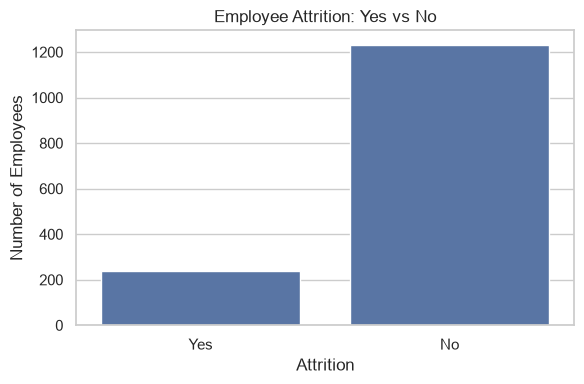

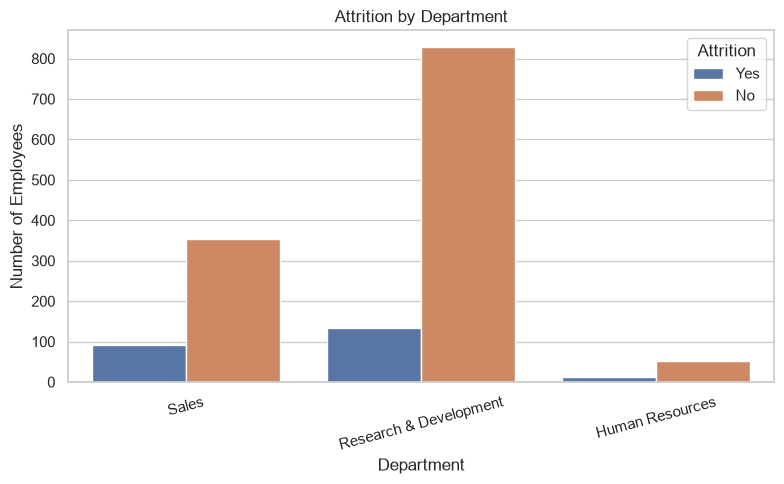

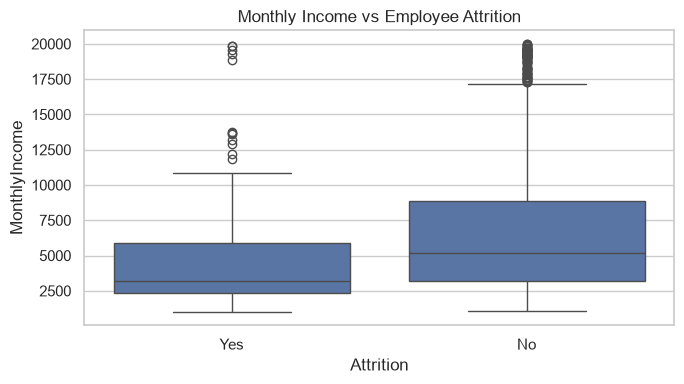

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Chart 1: Attrition count
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition: Yes vs No")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

# Chart 2: Department-wise attrition
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Department", hue="Attrition")
plt.title("Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Chart 3: Monthly income by attrition
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome")
plt.title("Monthly Income vs Employee Attrition")
plt.tight_layout()
plt.show()

In [9]:
print("Total missing values:",
      df.isnull().sum().sum())
print(df["Attrition"].value_counts())


Total missing values: 0
Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [10]:
import pandas as pd

df=pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (1470, 35)


In [11]:
print("Total missing values:",
      df.isnull().sum().sum())
print(df["Attrition"].value_counts())

Total missing values: 0
Attrition
No     1233
Yes     237
Name: count, dtype: int64


EMPLOYEE ATTRITION KPI REPORT
-----------------------------------
Total Employees: 1470
Employees Left: 237
Employees Stayed: 1233
Attrition Rate: 16.12 %

Department-wise attrition:
Attrition                No  Yes
Department                      
Human Resources          51   12
Research & Development  828  133
Sales                   354   92

Average Monthly Income:
Attrition
No     6832.74
Yes    4787.09
Name: MonthlyIncome, dtype: float64


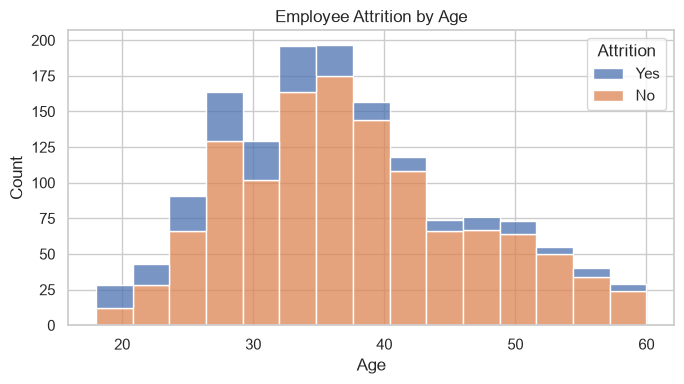

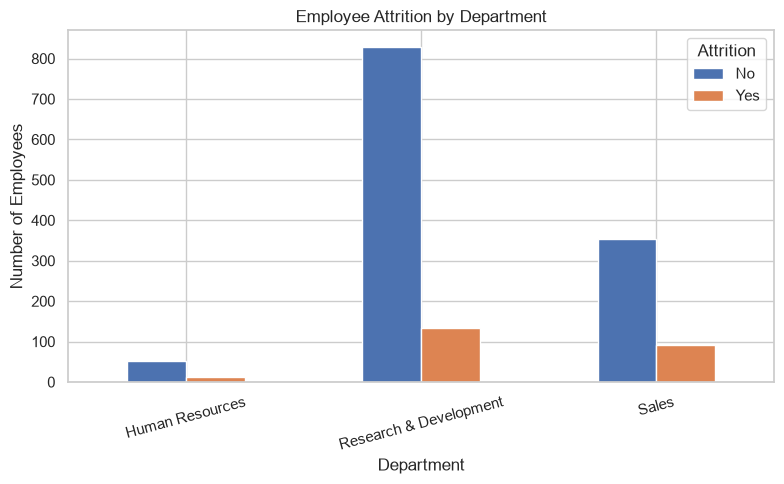

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Overall KPIs
total_employees = len(df)
employees_left = (df["Attrition"] == "Yes").sum()
attrition_rate = employees_left / total_employees * 100

print("EMPLOYEE ATTRITION KPI REPORT")
print("-" * 35)
print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Employees Stayed:", total_employees - employees_left)
print("Attrition Rate:", round(attrition_rate, 2), "%")

# Attrition by department
print("\nDepartment-wise attrition:")
print(pd.crosstab(df["Department"], df["Attrition"]))

# Average salary by attrition
print("\nAverage Monthly Income:")
print(df.groupby("Attrition")["MonthlyIncome"].mean().round(2))

# Attrition by age
plt.figure(figsize=(7, 4))
sns.histplot(
    data=df, x="Age", hue="Attrition",
    multiple="stack", bins=15
)
plt.title("Employee Attrition by Age")
plt.tight_layout()
plt.show()

# Attrition by department
pd.crosstab(
    df["Department"], df["Attrition"]
).plot(kind="bar", figsize=(8, 5))

plt.title("Employee Attrition by Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

C:\Users\uyyala siddardha\AppData\Local\Temp\ipykernel_27756\368764730.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object"]).columns


MODEL: LOGISTIC REGRESSION
Test accuracy: 75.17 %

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.92      0.77      0.84       247
        Left       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294



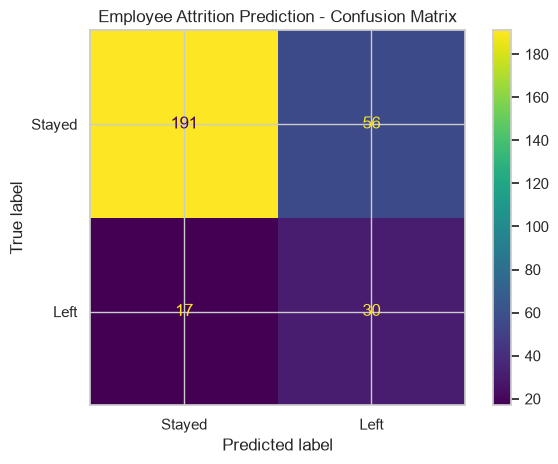

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_sample_weight

# Target and features
X = df.drop(columns=["Attrition", "EmployeeCount", "EmployeeNumber", "Over18", "StandardHours"])
y = (df["Attrition"] == "Yes").astype(int)

# Separate numeric and categorical columns
categorical_cols = X.select_dtypes(include=["object"]).columns
numeric_cols = X.select_dtypes(exclude=["object"]).columns

# Preprocessing
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

# Split data while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Build model; class weights address class imbalance
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ))
])

# Train and predict
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("MODEL: LOGISTIC REGRESSION")
print("Test accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=["Stayed", "Left"], zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Stayed", "Left"]
)
plt.title("Employee Attrition Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

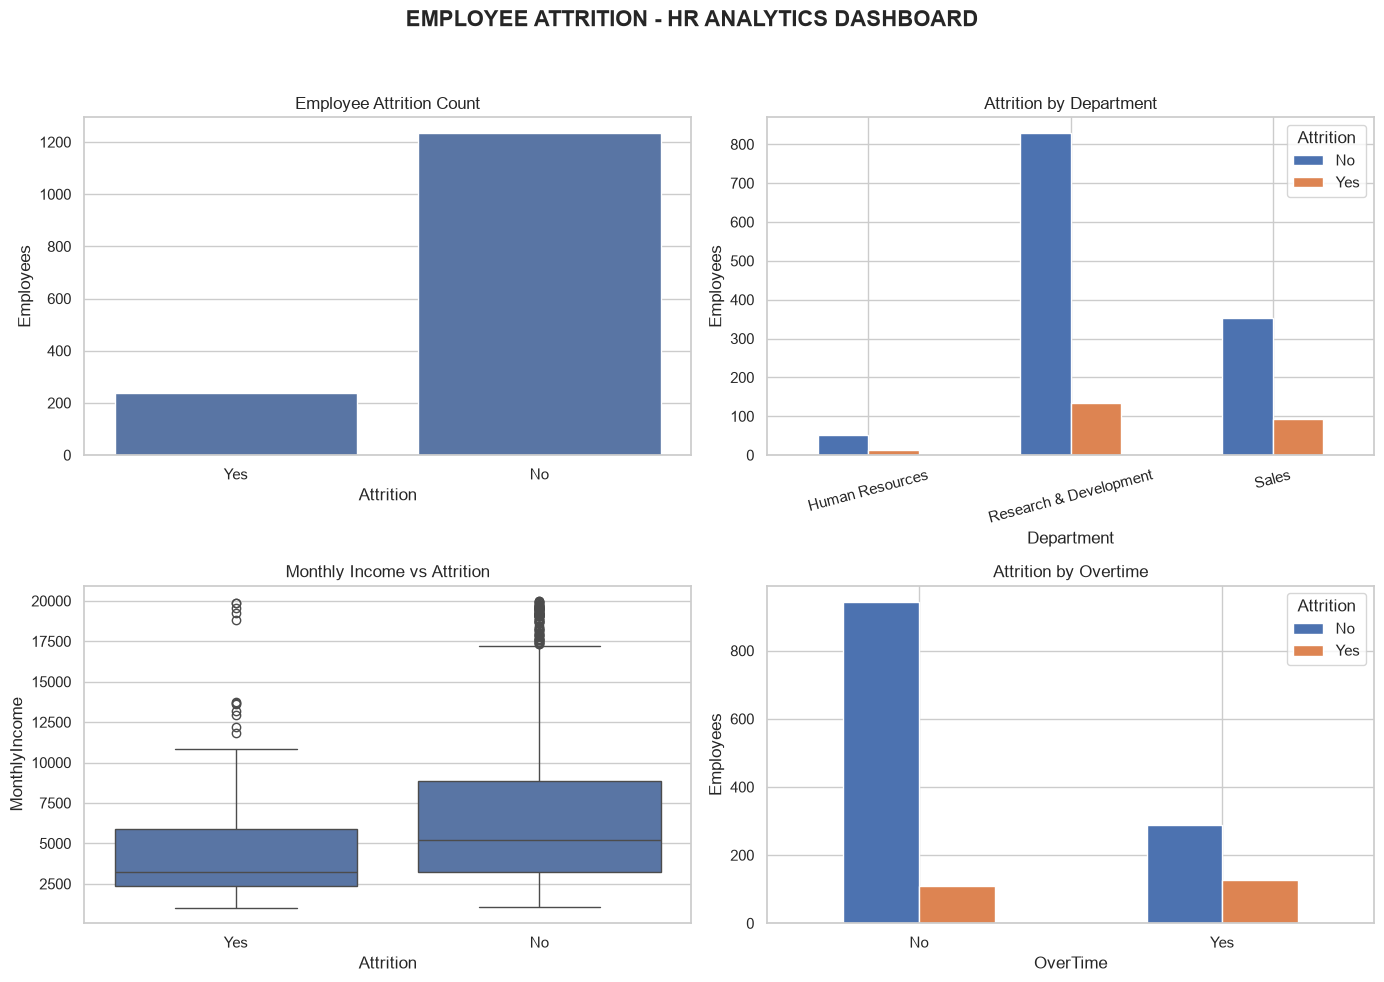

In [14]:
# HR Dashboard - KPI Charts
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("EMPLOYEE ATTRITION - HR ANALYTICS DASHBOARD",
             fontsize=16, fontweight="bold")

# KPI 1: Attrition distribution
sns.countplot(data=df, x="Attrition", ax=axes[0, 0])
axes[0, 0].set_title("Employee Attrition Count")
axes[0, 0].set_xlabel("Attrition")
axes[0, 0].set_ylabel("Employees")

# KPI 2: Department attrition counts
dept = pd.crosstab(df["Department"], df["Attrition"])
dept.plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Attrition by Department")
axes[0, 1].set_ylabel("Employees")
axes[0, 1].tick_params(axis="x", rotation=15)

# KPI 3: Monthly income comparison
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome",
            ax=axes[1, 0])
axes[1, 0].set_title("Monthly Income vs Attrition")

# KPI 4: Attrition by overtime
overtime = pd.crosstab(df["OverTime"], df["Attrition"])
overtime.plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Attrition by Overtime")
axes[1, 1].set_ylabel("Employees")
axes[1, 1].tick_params(axis="x", rotation=0)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [15]:
# Final Business Insights
department_rate = (
    df.assign(Left=(df["Attrition"] == "Yes").astype(int))
      .groupby("Department")["Left"]
      .agg(["sum", "count"])
)

department_rate["Attrition_Rate_%"] = (
    department_rate["sum"] / department_rate["count"] * 100
)

overtime_rate = (
    df.groupby("OverTime")["Attrition"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

print("DEPARTMENT ATTRITION RATE (%)")
print(department_rate.round(2))

print("\nATTRITION RATE BY OVERTIME (%)")
print(overtime_rate.round(2))

print("\nFINAL PROJECT SUMMARY")
print("Total Employees:", len(df))
print("Employees Left:", (df["Attrition"] == "Yes").sum())
print("Overall Attrition Rate:",
      round((df["Attrition"] == "Yes").mean() * 100, 2), "%")
print("Model Test Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

DEPARTMENT ATTRITION RATE (%)
                        sum  count  Attrition_Rate_%
Department                                          
Human Resources          12     63             19.05
Research & Development  133    961             13.84
Sales                    92    446             20.63

ATTRITION RATE BY OVERTIME (%)
OverTime
No     10.44
Yes    30.53
Name: Attrition, dtype: float64

FINAL PROJECT SUMMARY
Total Employees: 1470
Employees Left: 237
Overall Attrition Rate: 16.12 %
Model Test Accuracy: 75.17 %
